# Ray Tracing in One Weekend

In [1]:
using IJulia
using Images
using LinearAlgebra
using Random

## 4. Rays, a Simple Camera, and Background

### 4.1. The ray Class

$$ P(t) = \boldsymbol{A} + t\boldsymbol{B} $$

In [2]:
function ray(origin::C, direction::C, parameter::T)::C where {T <: Number, C <: AbstractVector{T}}
    return origin + parameter * direction
end

ray (generic function with 1 method)

In [3]:
function convert_to_unit_vector(vector::C)::C where {T <: Number, C <: AbstractVector{T}}
    return vector ./ sqrt(dot(vector, vector))
end

convert_to_unit_vector (generic function with 1 method)

In [4]:
function ray_color(direction::C)::RGB{T} where {T <: AbstractFloat, C <: AbstractVector{T}}
    unit_direction = convert_to_unit_vector(direction)
    parameter = (unit_direction[2] + one(T)) / 2
    return RGB(((one(T) - parameter) * ones(typeof(unit_direction[2]), 3) + parameter * [0.5, 0.7, 1.0])...)
end

ray_color (generic function with 1 method)

#### notice!
$$
    \boldsymbol{焦点距離}(focal\_length) \neq \boldsymbol{集束距離}(focus\_distance)
$$

aspect_ratio = 16.0 / 9.0
image_width = UInt(384)
image_height = UInt(image_width / aspect_ratio)
viewport_height = 2.0
viewport_width = aspect_ratio * viewport_height
focal_length = 1.0
origin = zeros(Float64, 3)
horizontal = [viewport_width, 0, 0]
vertical = [0, viewport_height, 0]
lower_left_corner = origin - horizontal./2 - vertical./2 - [0, 0, focal_length]

#### 線形ブレンド(linear blend)/線形補完(linear interpolation)/lerp

$$
    color(t) = \begin{cases}
        blue (startValue) & t=1.0 \\
        white (endValue) & t=0.0 \\
        (1-t)blue + t\dot white & othiewise
    \end{cases}
$$

In [6]:
function render_color!(buffer::C)::C where {T <: AbstractFloat, C <: AbstractMatrix{RGB{T}}}
    for i = 1:image_width
        for j = 1:image_height
            u = AbstractFloat(i-1) / (image_width-1)
            v = AbstractFloat(image_height - j) / (image_height-1)
            direction = lower_left_corner + u .* horizontal + v .* vertical - origin
            pixel = ray_color(direction)
            buffer[j, i] = pixel
        end
    end
    return buffer
end

render_color! (generic function with 1 method)

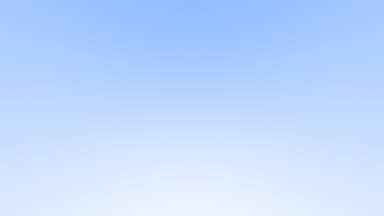

In [7]:
buffer = zeros(RGB{Float64}, image_height, image_width)
render_color!(buffer)
buffer

## 5. Adding a Sphere

### 5.1 Ray-Sphere Intersection

原点中心で半径$R$の球は$x^2+y^2+z^2=R^2$と表される。

$(x,y,z)$がこの球上にある時、これが成立。

球の内側である場合$x^2+y^2+z^2<R^2$
外側である場合$x^2+y^2+z^2>R^2$
が成立。

球の中心を$(C_x,C_y,C_z)$と表すと、
$$
    (x-C_x)^2 + (y-C_y)^2 + (z-C_z)^2 = r^2
$$
球の中心$\boldsymbol{C}=(C_x,C_y,C_z)$から点$P=(x,y,z)$へのベクトルは$(\boldsymbol{P}-\boldsymbol{C})$と表せるので
$$
    (\boldsymbol{P}-\boldsymbol{C}) \cdot (\boldsymbol{P}-\boldsymbol{C}) = r^2
$$
これは「任意の点$P$がこれを満たす時、点$P$は球面上にある」

レイ$P(t) = \boldsymbol{A} + t\boldsymbol{B}$がこれを満たすとき
$$
    \begin{align}
        (P(t) - \boldsymbol{C}) \cdot (P(t) - \boldsymbol{C}) = r^2 &\Leftrightarrow &(\boldsymbol{A} + t\boldsymbol{b} - \boldsymbol{C}) \cdot (\boldsymbol{A} + t\boldsymbol{b} - \boldsymbol{C}) &= r^2 &(\because 定義) \\
        &\Leftrightarrow &t^2 \boldsymbol{b} \cdot \boldsymbol{b} + 2t\boldsymbol{b} \cdot (\boldsymbol{A} - \boldsymbol{C}) + (\boldsymbol{A} - \boldsymbol{C}) \cdot (\boldsymbol{A} - \boldsymbol{C}) &= r^2 \\
        &\Leftrightarrow &t^2 \boldsymbol{b} \cdot \boldsymbol{b} + 2t\boldsymbol{b} \cdot (\boldsymbol{A} - \boldsymbol{C}) + (\boldsymbol{A} - \boldsymbol{C}) \cdot (\boldsymbol{A} - \boldsymbol{C}) - r^2 &= 0
    \end{align}
$$
これは未知の$t$に関する二次方程式である。

### 5.2 Creating Our First Raytraced Image

In [8]:
function hit_sphere(center::C, radius::T,
        origin::C, direction::C)::Bool where {T <: Number, C <: AbstractVector{T}}
    oc = origin - center
    a = dot(direction, direction)
    b = 2.0 * dot(oc, direction)
    c = dot(oc, oc) - radius * radius
    discriminant = b * b - 4a * c
    return discriminant > 0
end

hit_sphere (generic function with 1 method)

In [9]:
function ray_color(origin::C, direction::C)::RGB{T} where {T <: AbstractFloat, C <: AbstractVector{T}}
    if hit_sphere([0.0, 0.0, -1.0], 0.5, origin, direction)
        return RGB([1.0, 0.0, 0.0]...)
    end
    return ray_color(direction)
end

ray_color (generic function with 2 methods)

In [10]:
function render_color!(buffer::C)::C where {T <: AbstractFloat, C <: AbstractMatrix{RGB{T}}}
    for i = 1:image_width
        for j = 1:image_height
            u = AbstractFloat(i-1) / (image_width-2)
            v = AbstractFloat(image_height-j) / (image_height-2)
            direction = lower_left_corner + u .* horizontal + v .* vertical - origin;
            pixel = ray_color(origin, direction)
            buffer[j, i] = pixel
        end
    end
    return buffer
end

render_color! (generic function with 1 method)

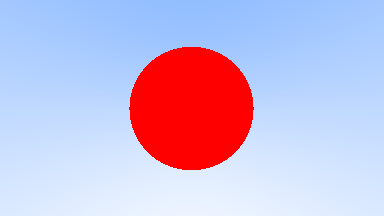

In [11]:
fill!(buffer, 0)
render_color!(buffer)
buffer

## 6. Surface Normals and Multiple Objects

### 6.1. Shading with Surface Normals

In [12]:
function hit_sphere_or(center::C, radius::T,
        origin::C, direction::C
        )::Union{T, Nothing} where {T <: Number, C <: AbstractVector{T}}
    oc = origin - center
    a = dot(direction, direction)
    b = 2.0 * dot(oc, direction)
    c = dot(oc, oc) - radius * radius
    discriminant = b * b - 4a * c
    if discriminant < 0
        return
    else
        return ( -b - sqrt(discriminant)) / (2.0a)
    end
end

hit_sphere_or (generic function with 1 method)

In [13]:
function ray_color_with_sphere_normals(hit_sphere,
        center::C, radius::T,
        origin::C, direction::C
        )::RGB{T} where {T <: AbstractFloat, C <: AbstractVector{T}}
    parameter_on_sphere = hit_sphere(center, radius, origin, direction)
    if !isnothing(parameter_on_sphere)
        normal = convert_to_unit_vector(ray(origin, direction, parameter_on_sphere) - center)
        return RGB(((normal .+ 1) ./ 2)...)
    end
    parameter = (convert_to_unit_vector(direction)[2] + 1) ./ 2
    return RGB(((1.0 - parameter) * ones(T, 3) + parameter * [0.5, 0.7, 1.0])...)
end

ray_color_with_sphere_normals (generic function with 1 method)

In [14]:
function direction_at_uv(i::T, j::T)::AbstractVector{<: Number} where T <: Unsigned
    u = AbstractFloat(i-1) / (image_width-2)
    v = AbstractFloat(image_height - j) / (image_height-2)
    return lower_left_corner + u .* horizontal + v .* vertical - origin
end

direction_at_uv (generic function with 1 method)

In [15]:
function render_color!(direction_at,
        ray_color,
        buffer::C
        )::C where {T <: AbstractFloat, C <: AbstractMatrix{RGB{T}}}
    for i = 1:image_width
        for j = 1:image_height
            pixel = ray_color(origin, direction_at(i, j))
            buffer[j, i] = pixel
        end
    end
    return buffer
end

render_color! (generic function with 2 methods)

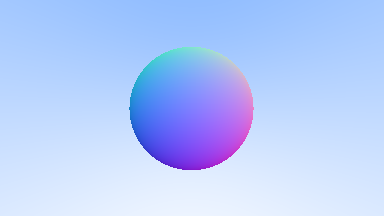

In [16]:
render_color!(direction_at_uv,
    ((orig, dir) -> ray_color_with_sphere_normals(
            hit_sphere_or, [0, 0, -1.0], 0.5, orig, dir)),
    buffer)
buffer

### 6.2. Simplifying the Ray-Sphere Intersection Code

同じベクトル同士の内積はベクトルの$L^2$ノルムに等しい。

$b=2h$とおくと
$$
    \begin{align}
        \frac{-b\pm\sqrt{b^2-4ac}}{2a} &= \frac{-2h\pm\sqrt{(2h)^2-4ac}}{2a} \\
        &= \frac{-h\pm\sqrt{h^2-ac}}{a}
    \end{align}
$$

In [17]:
function hit_sphere_improved(center::C, radius::T,
        origin::C, direction::C
        )::Union{T, Nothing} where {T <: Number, C <: AbstractVector{T}}
    oc = origin - center
    a = dot(direction, direction)
    half_b = dot(oc, direction)
    c = dot(oc, oc) - radius * radius
    discriminant = half_b * half_b - a * c
    if discriminant < 0
        return
    else
        return ( -b - sqrt(discriminant)) / a
    end
end

hit_sphere_improved (generic function with 1 method)

### 6.3. An Abstraction for Hittable Objects

In [18]:
struct Ray{T <: Number, C <: AbstractVector{T}}
    origin::C
    direction::C
end

In [19]:
function fly(ray::Ray{T, C}, t::T)::C where {T <: Number, C <: AbstractVector{T}}
    return ray.origin + t .* ray.direction
end

fly (generic function with 1 method)

In [20]:
struct HitRecord{T <: Number, C <: AbstractVector{T}}
    position::C
    normal::C
    t::T
end

In [21]:
struct Sphere{T <: Number, C <: AbstractVector{T}}
    center::C
    radius::T
end

In [22]:
function hit_within(sphere::Sphere{T, C},
        ray::Ray{T, C},
        t_min::T, t_max::T, t
        )::Union{HitRecord{T}, Nothing} where {T <: Number, C <: AbstractVector{T}}
    if t_min < t < t_max
        position = fly(ray, t)
        return HitRecord(
            position,
            (position - sphere.center) / sphere.radius,
            t)
    end
end

hit_within (generic function with 1 method)

In [23]:
function hit(sphere::Sphere{T, C},
        ray::Ray{T, C},
        t_min::T, t_max::T
        )::Union{HitRecord{T}, Nothing} where {T <: Number, C <: AbstractVector{T}}
    oc = ray.origin - sphere.center
    a = dot(ray.direction, ray.direction)
    half_b = dot(oc, ray.direction)
    c = dot(oc, oc) - sphere.radius * sphere.radius
    discriminant = half_b * half_b - a * c
    if discriminant > 0
        root = sqrt(discriminant)
        smaller = (-b - root) / a
        return hit_within(sphere, ray, t_min, t_max, smaller)
        bigger = (-b + root) / a
        return hit_within(sphere, ray, t_min, t_max, bigger)
    end
end

hit (generic function with 1 method)

### 6.4. Front Faces Versus Back Faces

In [24]:
struct InnerHitRecord{T <: Number, C <: AbstractVector{T}}
    position::C
    normal::C
    t::T
end

In [25]:
struct OuterHitRecord{T <: Number, C <: AbstractVector{T}}
    position::C
    normal::C
    t::T
end

In [26]:
FrontFacedNormalHitRecord{T} = Union{InnerHitRecord{T}, OuterHitRecord{T}} where T <: Number

FrontFacedNormalHitRecord (alias for Union{InnerHitRecord{T, C} where C<:AbstractArray{T, 1}, OuterHitRecord{T, C} where C<:AbstractArray{T, 1}} where T<:Number)

In [27]:
function is_face_normal(ray::Ray{T, C},
        outward_normal::C
        )::Bool where {T <: Number, C <: AbstractVector{T}}
    return dot(ray.direction, outward_normal) < zero(T)
end

is_face_normal (generic function with 1 method)

In [28]:
function hit_within_or(sphere::Sphere{T, C},
        ray::Ray{T, C},
        t_min::T, t_max::T, t::T
        )::Union{FrontFacedNormalHitRecord{T}, Nothing} where {T <: Number, C <: AbstractVector{T}}
    if t_min < t < t_max
        position = fly(ray, t)
        outward_normal = (position - sphere.center) / sphere.radius
        if is_face_normal(ray, outward_normal)
            return OuterHitRecord(position, outward_normal, t)
        else
            return InnerHitRecord(position, -outward_normal, t)
        end
    end
    return
end

hit_within_or (generic function with 1 method)

In [29]:
function hit_or(sphere::Sphere{T, C},
        ray::Ray{T, C},
        t_min::T, t_max::T
        )::Union{FrontFacedNormalHitRecord{T}, Nothing} where {T <: Number, C <: AbstractVector{T}}
    oc = ray.origin - sphere.center
    a = dot(ray.direction, ray.direction)
    half_b = dot(oc, ray.direction)
    c = dot(oc, oc) - sphere.radius * sphere.radius
    discriminant = half_b * half_b - a * c
    if discriminant > 0
        root = sqrt(discriminant)
        smaller = (-half_b - root) / a
        return hit_within_or(sphere, ray, t_min, t_max, smaller)
        bigger = (-half_b + root) / a
        return hit_within_or(sphere, ray, t_min, t_max, bigger)
    end
end

hit_or (generic function with 1 method)

### 6.5. A List of Hittable Objects

In [30]:
struct Hittables
    render_objects::AbstractArray
end

In [31]:
function hit_or(hittables::Hittables,
        ray::Ray{T, C},
        t_min::T, t_max::T
        )::Union{FrontFacedNormalHitRecord{T}, Nothing} where {T <: Number, C <: AbstractVector{T}}
    rec = nothing
    temp_rec = nothing
    closest_so_far = t_max
    for target ∈ hittables.render_objects
        temp_rec = hit_or(target, ray, t_min, closest_so_far)
        if !isnothing(temp_rec)
            rec = temp_rec
            closest_so_far = temp_rec.t 
        end
    end
    return rec
end

hit_or (generic function with 2 methods)

In [32]:
function ray_color(hittables::Hittables,
        ray::Ray{T, C}
        )::RGB{T} where {T <: AbstractFloat, C <: AbstractVector{T}}
    rec = hit_or(hittables, ray, 0.0, Inf)
    if isnothing(rec)
        return ray_color(ray.direction)
    else
        return RGB((0.5(rec.normal + [1.0, 1.0, 1.0]))...)
    end
end

ray_color (generic function with 3 methods)

In [33]:
spheres = [Sphere([0, 0, -1.0], 0.5), Sphere([0, -100.5, -1], 100.0)]

2-element Vector{Sphere{Float64, Vector{Float64}}}:
 Sphere{Float64, Vector{Float64}}([0.0, 0.0, -1.0], 0.5)
 Sphere{Float64, Vector{Float64}}([0.0, -100.5, -1.0], 100.0)

In [34]:
function render_color!(direction_at,
        ray_color,
        hittable,
        origin::C,
        buffer::D
        )::D where {T <: AbstractFloat, C <: AbstractVector{T}, D <: AbstractMatrix{RGB{T}}}
    for i = 1:image_width
        for j = 1:image_height
            pixel = ray_color(hittable, Ray(origin, direction_at(i, j)))
            buffer[j, i] = pixel
        end
    end
    return buffer
end

render_color! (generic function with 3 methods)

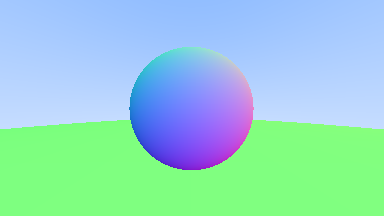

In [35]:
render_color!(direction_at_uv, ray_color, Hittables(spheres), [0.0, 0.0, 0.0], buffer)
buffer

## 7. Antialiasing

### 7.2. Generating Pixels with Multiple Samples

In [36]:
function calc_lower_left_corner(focal_length::T,
        origin::C,
        horizontal::C, vertical::C
        ) where {T <: Number, C <: AbstractVector{T}}
    return origin - horizontal ./ 2 - vertical ./ 2 - [zero(T), zero(T), focal_length]
end

calc_lower_left_corner (generic function with 1 method)

In [37]:
struct Camera{T <: Number, U <: Unsigned, C <: AbstractVector{T}}
    image_height::U
    image_width::U
    origin::C
    horizontal::C
    vertical::C
    lower_left_corner::C
end

In [38]:
function calc_uv!(T::Type,
        camera,
        i::U, j::U,
        random_generator::AbstractRNG
        )::Tuple{T, T} where {U <: Unsigned}
    return ((T(i) + rand(random_generator, T) - one(T)) / (camera.image_width - one(T)),
        (camera.image_height + rand(random_generator, T) - T(j)) / (camera.image_height - one(T)))
end

calc_uv! (generic function with 1 method)

In [39]:
function get_ray(camera,
        u::T, v::T,
        )::Ray where {T <: Number}
    return Ray(camera.origin,
        camera.lower_left_corner
        + u .* camera.horizontal
        + v .* camera.vertical
        - camera.origin)
end

get_ray (generic function with 1 method)

In [40]:
function render_color!(calc_uv!,
        get_ray,
        ray_color,
        hittable,
        camera,
        samples_per_pixel::U,
        random_generator::AbstractRNG,
        buffer::C
        )::C where {T <: AbstractFloat, U <: Unsigned,
            C <: AbstractMatrix{RGB{T}}}
    for i = 1:camera.image_width
        for j = 1:camera.image_height
            color = zero(RGB)
            for s = 1:samples_per_pixel
                color += ray_color(hittable, get_ray(camera, calc_uv!(T, camera, i, j, random_generator)...))
            end
            color = color ./ samples_per_pixel
            pixel = RGB(clamp(color.r, zero(T), one(T)),
                clamp(color.g, zero(T), one(T)),
                clamp(color.b, zero(T), one(T)))
            buffer[j, i] = pixel
        end
    end
    return buffer
end

render_color! (generic function with 4 methods)

In [41]:
def_cam = Camera(UInt64(image_width / aspect_ratio),
    image_width,
    origin,
    horizontal,
    vertical,
    calc_lower_left_corner(focal_length,
        origin,
        horizontal, vertical))

Camera{Float64, UInt64, Vector{Float64}}(0x00000000000000d8, 0x0000000000000180, [0.0, 0.0, 0.0], [3.5555555555555554, 0.0, 0.0], [0.0, 2.0, 0.0], [-1.7777777777777777, -1.0, -1.0])

In [42]:
samples_per_pixel = UInt(100)
random_seed = 5103
# 3315153
random_generator = MersenneTwister(5103)

MersenneTwister(5103)

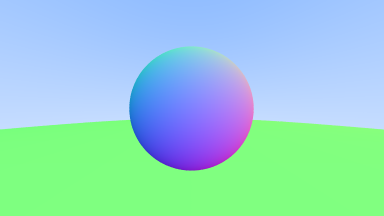

In [43]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    Hittables(spheres),
    def_cam,
    samples_per_pixel,
    random_generator,
    buffer)
buffer

## 8. Diffuse Materials

### 8.1. A Simple Diffuse Material

In [44]:
function signed_unit_random(T::Type, random_generator::AbstractRNG)::T
    return 2rand(random_generator, T) - one(T)
end

signed_unit_random (generic function with 1 method)

In [45]:
function random_in_unit_sphere(T::Type, random_generator::AbstractRNG
        )::AbstractArray{T}
    while true
        p = [signed_unit_random(T, random_generator),
            signed_unit_random(T, random_generator),
            signed_unit_random(T, random_generator)]
        if dot(p, p) >= one(T)
            continue
        end
        return p
    end
end

random_in_unit_sphere (generic function with 1 method)

In [46]:
function ray_color(hittables::Hittables,
        ray::Ray{T, C}
        )::RGB{T} where {T <: AbstractFloat, C <: AbstractVector{T}}
    rec = hit_or(hittables, ray, 0.0, Inf)
    if isnothing(rec)
        return ray_color(ray.direction)
    else
        target = rec.position + rec.normal + random_in_unit_sphere(T, random_generator)
        return 0.5(ray_color(hittables, Ray(rec.position, target - rec.position)))
    end
end

ray_color (generic function with 3 methods)

### 8.2. Limiting the Number of Child Rays

In [47]:
function ray_color(direction::C, depth::U
        )::RGB{T} where {T <: AbstractFloat, U <: Signed, C <: AbstractVector{T}}
    if depth <= 0
        return RGB(zero(T), zero(T), zero(T))
    end
    
    unit_direction = convert_to_unit_vector(direction)
    one = oneunit(unit_direction[2])
    parameter = (unit_direction[2] + one) / 2
    return RGB(((one - parameter) * ones(typeof(unit_direction[2]), 3) + parameter * [0.5, 0.7, 1.0])...)
end

ray_color (generic function with 4 methods)

In [48]:
function ray_color(hittables::Hittables,
        ray::Ray{T, C},
        depth::U,
        random_generator::AbstractRNG
        )::RGB{T} where {T <: AbstractFloat, U <: Signed, C <: AbstractVector{T}}
    if depth <= 0
        return RGB(zero(T), zero(T), zero(T))
    end
    
    rec = hit_or(hittables, ray, 0.0, Inf)
    if isnothing(rec)
        return ray_color(ray.direction, depth - one(U))
    else
        target = rec.position + rec.normal + random_in_unit_sphere(T, random_generator)
        return RGB((0.5(
                    ray_color(hittables,
                        Ray(rec.position, target - rec.position),
                        depth - one(U),
                        random_generator))))
    end
end

ray_color (generic function with 5 methods)

In [49]:
function render_color!(calc_uv!,
        get_ray,
        ray_color,
        hittable,
        camera,
        samples_per_pixel::U,
        max_depth::V,
        random_generator::AbstractRNG,
        buffer::C
        )::C where {T <: AbstractFloat, U <: Unsigned, V <: Signed,
            C <: AbstractMatrix{RGB{T}}}
    for i = 1:camera.image_width
        for j = 1:camera.image_height
            color = zero(RGB)
            for s = 1:samples_per_pixel
                color += ray_color(hittable,
                    get_ray(camera,
                        calc_uv!(T, camera, i, j, random_generator)...),
                max_depth,
                random_generator)
            end
            color = color ./ samples_per_pixel
            pixel = RGB(clamp(color.r, zero(T), one(T)),
                clamp(color.g, zero(T), one(T)),
                clamp(color.b, zero(T), one(T)))
            buffer[j, i] = pixel
        end
    end
    return buffer
end

render_color! (generic function with 5 methods)

In [50]:
max_depth = 50

50

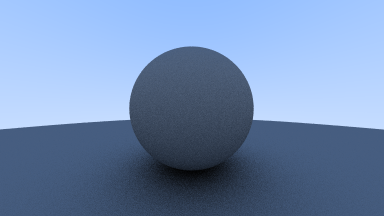

In [51]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    Hittables(spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

### 8.3. Using Gamma Correction for Accurate Color Intensity
skipped

### 8.4. Fixing Shadow Acne

In [52]:
function ray_color(hittables::Hittables,
        ray::Ray{T, C},
        depth::U,
        random_generator::AbstractRNG
        )::RGB{T} where {T <: AbstractFloat, U <: Signed, C <: AbstractVector{T}}
    if depth <= 0
        return RGB(zero(T), zero(T), zero(T))
    end
    
    rec = hit_or(hittables, ray, 0.001, Inf)
    if isnothing(rec)
        return ray_color(ray.direction, depth - one(U))
    else
        target = rec.position + rec.normal + random_in_unit_sphere(T, random_generator)
        return RGB((0.5(
                    ray_color(hittables,
                        Ray(rec.position, target - rec.position),
                        depth - one(U),
                        random_generator))))
    end
end

ray_color (generic function with 5 methods)

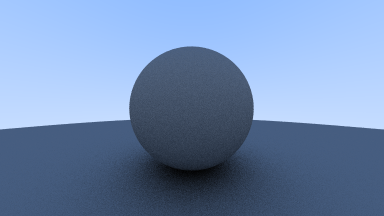

In [53]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    Hittables(spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

### 8.5. True Lambertian Reflection

In [54]:
function random_unit_vector(T::Type, random_generator::AbstractRNG
        )::AbstractArray{T}
    return convert_to_unit_vector(random_in_unit_sphere(T, random_generator))
end

random_unit_vector (generic function with 1 method)

In [55]:
function ray_color(hittables::Hittables,
        ray::Ray{T, C},
        depth::U,
        random_generator::AbstractRNG
        )::RGB{T} where {T <: AbstractFloat, U <: Signed, C <: AbstractVector{T}}
    if depth <= 0
        return RGB(zero(T), zero(T), zero(T))
    end
    
    rec = hit_or(hittables, ray, 0.001, Inf)
    if isnothing(rec)
        return ray_color(ray.direction, depth - one(U))
    else
        target = rec.position + rec.normal + random_unit_vector(T, random_generator)
        return RGB((0.5(
                    ray_color(hittables,
                        Ray(rec.position, target - rec.position),
                        depth - one(U),
                        random_generator))))
    end
end

ray_color (generic function with 5 methods)

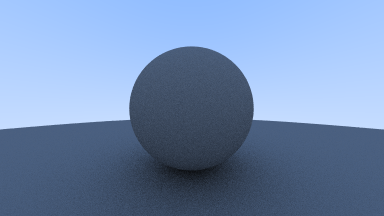

In [56]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    Hittables(spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

### 8.6. An Alternative Diffuse Formulation

In [57]:
function random_in_hemisphere(normal::C,
        random_generator::AbstractRNG
        )::C where {T <: Number, C <: AbstractVector{T}}
    in_unit_sphere = random_in_unit_sphere(T, random_generator)
    if dot(in_unit_sphere, normal) > zero(T)
        return in_unit_sphere
    else
        return -in_unit_sphere
    end
end

random_in_hemisphere (generic function with 1 method)

In [58]:
function ray_color(diffusing,
        hittables::Hittables,
        ray::Ray{T, C},
        depth::U,
        random_generator::AbstractRNG
        )::RGB{T} where {T <: AbstractFloat, U <: Signed, C <: AbstractVector{T}}
    if depth <= 0
        return RGB(zero(T), zero(T), zero(T))
    end
    
    rec = hit_or(hittables, ray, 0.001, Inf)
    if isnothing(rec)
        return ray_color(ray.direction, depth - one(U))
    else
        target = rec.position + diffusing(rec.normal, random_generator)
        return RGB((0.5(
                    ray_color(hittables,
                        Ray(rec.position, target - rec.position),
                        depth - one(U),
                        random_generator))))
    end
end

ray_color (generic function with 6 methods)

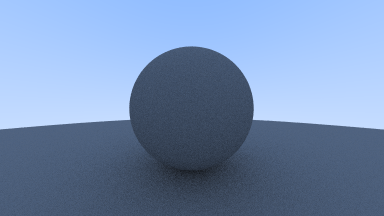

In [59]:
render_color!(calc_uv!,
    get_ray,
    (h,r,d,rng) -> ray_color(random_in_hemisphere, h,r,d,rng),
    Hittables(spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

In [60]:
function ray_color(diffusing,
        hittables::Hittables,
        ray::Ray{T, C},
        depth::U,
        random_generator::AbstractRNG
        )::RGB{T} where {T <: AbstractFloat, U <: Signed, C <: AbstractVector{T}}
    if depth <= 0
        return RGB(zero(T), zero(T), zero(T))
    end
    
    rec = hit_or(hittables, ray, 0.001, Inf)
    if isnothing(rec)
        return ray_color(ray.direction)
    else
        target = rec.position + rec.normal + diffusing(T, random_generator)
        return RGB((0.5(
                    ray_color(hittables,
                        Ray(rec.position, target - rec.position),
                        depth - one(U),
                        random_generator))))
    end
end

ray_color (generic function with 6 methods)

## 9. Metal

### 9.1. An Abstract Class for Materials

In [61]:
abstract type Material end

### 9.2. A Data Structure to Describe Ray-Object Intersections

In [62]:
struct InnerHitRecordWithMat{T <: Number, C <: AbstractVector{T}, D <: Material}
    position::C
    normal::C
    t::T
    material::D
end

In [63]:
struct OuterHitRecordWithMat{T <: Number, C <: AbstractVector{T}, D <: Material}
    position::C
    normal::C
    t::T
    material::D
end

In [64]:
FrontFacedNormalHitRecordWithMat{T, C, D} =
    Union{InnerHitRecordWithMat{T, C, D},
        OuterHitRecordWithMat{T, C, D}} where {T <: Number, C <: AbstractVector{T}, D <: Material}

FrontFacedNormalHitRecordWithMat{T} where T<:Number (alias for Union{InnerHitRecordWithMat{T, C, D}, OuterHitRecordWithMat{T, C, D}} where {T<:Number, C<:AbstractArray{T, 1}, D<:Material})

In [65]:
abstract type Hittable end

In [66]:
struct HittablesWithMat
    render_objects::AbstractArray{Hittable}
end

In [67]:
struct SphereWithMat{T <: Number, C <: AbstractVector{T}, D <: Material} <: Hittable
    center::C
    radius::T
    material::D
end

### 9.3. Modeling Light Scatter and Reflectance

In [68]:
struct Lambertian{T <: AbstractFloat} <: Material
    albedo::RGB{T}
end

In [69]:
function scatter(ray_in::Ray{T, C},
        rec::FrontFacedNormalHitRecordWithMat{T, C, Lambertian{T}},
        random_generator::AbstractRNG
        )::Tuple{Ray{T, C}, RGB{T}, Bool} where {T <: AbstractFloat, C <: AbstractVector{T}}
    scatter_direction = rec.normal + random_unit_vector(T, random_generator)
    return (Ray(rec.position, scatter_direction), rec.material.albedo, true)
end

scatter (generic function with 1 method)

### 9.4. Mirrored Light Reflection

In [70]:
function reflect(v::C, n::C)::C where {T <: Number, C <: AbstractVector{T}}
    return v - 2dot(v, n)n
end

reflect (generic function with 1 method)

In [71]:
struct Metal{T <: AbstractFloat} <: Material
    albedo::RGB{T}
end

In [72]:
function scatter(ray_in::Ray{T, C},
        rec::FrontFacedNormalHitRecordWithMat{T, C, Metal{T}},
        random_generator::AbstractRNG
        )::Tuple{Ray{T, C}, RGB{T}, Bool} where {T <: AbstractFloat, C <: AbstractVector{T}}
    reflected = reflect(convert_to_unit_vector(ray_in.direction), rec.normal)
    scattered = Ray(rec.position, reflected)
    return (scattered, rec.material.albedo, dot(scattered.direction, rec.normal) > 0)
end

scatter (generic function with 2 methods)

In [73]:
function ray_color(hittables::HittablesWithMat,
        ray::Ray{T, C},
        depth::U,
        random_generator::AbstractRNG
        )::RGB{T} where {T <: AbstractFloat, U <: Signed, C <: AbstractVector{T}}
    if depth <= 0
        return RGB(zero(T), zero(T), zero(T))
    end
    
    rec = hit_or(hittables, ray, 0.001, Inf)
    if isnothing(rec)
        return ray_color(ray.direction)
    else
        scattered_ray, attenuation, is_scattered = scatter(ray, rec, random_generator)
        if is_scattered
            color = ray_color(hittables, scattered_ray, depth - one(U), random_generator)
            return attenuation ⊙ color
        else
            return RGB(zero(T), zero(T), zero(T))
        end
    end
end

ray_color (generic function with 7 methods)

### 9.5. A Scene with Metal Spheres

In [74]:
mat_ground = Lambertian(RGB(0.8, 0.8, 0.0))
mat_center = Lambertian(RGB(0.7, 0.3, 0.3))
mat_left = Metal(RGB(0.8, 0.8, 0.8))
mat_right = Metal(RGB(0.8, 0.6, 0.2))

scene_with_metal_spheres = [SphereWithMat([0.0, -100.5, -1.0], 100.0, mat_ground),
    SphereWithMat([0.0, 0.0, -1.0], 0.5, mat_center),
    SphereWithMat([-1.0, 0.0, -1.0], 0.5, mat_left),
    SphereWithMat([1.0, 0.0, -1.0], 0.5, mat_right)]

4-element Vector{SphereWithMat{Float64, Vector{Float64}}}:
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.0, -100.5, -1.0], 100.0, Lambertian{Float64}(RGB{Float64}(0.8,0.8,0.0)))
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.0, 0.0, -1.0], 0.5, Lambertian{Float64}(RGB{Float64}(0.7,0.3,0.3)))
 SphereWithMat{Float64, Vector{Float64}, Metal{Float64}}([-1.0, 0.0, -1.0], 0.5, Metal{Float64}(RGB{Float64}(0.8,0.8,0.8)))
 SphereWithMat{Float64, Vector{Float64}, Metal{Float64}}([1.0, 0.0, -1.0], 0.5, Metal{Float64}(RGB{Float64}(0.8,0.6,0.2)))

In [75]:
function hit_within_or(sphere::SphereWithMat{T, C, D},
        ray::Ray{T, C},
        t_min::T, t_max::T, t::T
        )::Union{FrontFacedNormalHitRecordWithMat{T, C, D}, Nothing} where {T <: Number, C <: AbstractVector{T}, D <: Material}
    if t_min < t < t_max
        position = fly(ray, t)
        outward_normal = (position - sphere.center) / sphere.radius
        if is_face_normal(ray, outward_normal)
            return OuterHitRecordWithMat(position, outward_normal, t, sphere.material)
        else
            return InnerHitRecordWithMat(position, -outward_normal, t, sphere.material)
        end
    end
    return
end

hit_within_or (generic function with 2 methods)

In [76]:
function hit_or(sphere::SphereWithMat{T, C, D},
        ray::Ray{T, C},
        t_min::T, t_max::T
        )::Union{FrontFacedNormalHitRecordWithMat{T, C, D}, Nothing} where {T <: Number, C <: AbstractVector{T}, D <: Material}
    oc = ray.origin - sphere.center
    a = dot(ray.direction, ray.direction)
    half_b = dot(oc, ray.direction)
    c = dot(oc, oc) - sphere.radius * sphere.radius
    discriminant = half_b * half_b - a * c
    if discriminant > 0
        root = sqrt(discriminant)
        smaller = (-half_b - root) / a
        return hit_within_or(sphere, ray, t_min, t_max, smaller)
        bigger = (-half_b + root) / a
        return hit_within_or(sphere, ray, t_min, t_max, bigger)
    end
end

hit_or (generic function with 3 methods)

In [77]:
function hit_or(hittables::HittablesWithMat,
        ray::Ray{T, C},
        t_min::T, t_max::T
        )::Union{FrontFacedNormalHitRecordWithMat{T, C}, Nothing} where {T <: Number, C <: AbstractVector{T}}
    rec = nothing
    temp_rec = nothing
    closest_so_far = t_max
    for target ∈ hittables.render_objects
        temp_rec = hit_or(target, ray, t_min, closest_so_far)
        if !isnothing(temp_rec)
            rec = temp_rec
            closest_so_far = temp_rec.t 
        end
    end
    return rec
end

hit_or (generic function with 4 methods)

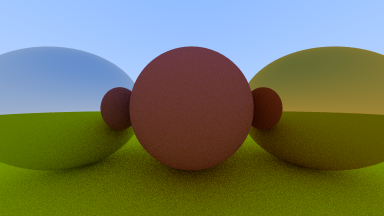

In [78]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    HittablesWithMat(scene_with_metal_spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

### 9.6. Fuzzy Reflection

In [79]:
struct FuzzyMetal{T <: AbstractFloat} <: Material
    albedo::RGB{T}
    fuzziness::T
end

In [80]:
function scatter(ray_in::Ray{T, C},
        rec::FrontFacedNormalHitRecordWithMat{T, C, FuzzyMetal{T}},
        random_generator::AbstractRNG
        )::Tuple{Ray{T, C}, RGB{T}, Bool} where {T <: AbstractFloat, C <: AbstractVector{T}}
    reflected = reflect(convert_to_unit_vector(ray_in.direction), rec.normal)
    scattered = Ray(rec.position, reflected + rec.material.fuzziness * random_in_unit_sphere(T, random_generator))
    return (scattered, rec.material.albedo, dot(scattered.direction, rec.normal) > 0)
end

scatter (generic function with 3 methods)

In [81]:
mat_ground = Lambertian(RGB(0.8, 0.8, 0.0))
mat_center = Lambertian(RGB(0.7, 0.3, 0.3))
mat_left = FuzzyMetal(RGB(0.8, 0.8, 0.8), 0.3)
mat_right = FuzzyMetal(RGB(0.8, 0.6, 0.2), 0.1)

scene_with_fuzzymetal_spheres = [SphereWithMat([0.0, -100.5, -1.0], 100.0, mat_ground),
    SphereWithMat([0.0, 0.0, -1.0], 0.5, mat_center),
    SphereWithMat([-1.0, 0.0, -1.0], 0.5, mat_left),
    SphereWithMat([1.0, 0.0, -1.0], 0.5, mat_right)]

4-element Vector{SphereWithMat{Float64, Vector{Float64}}}:
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.0, -100.5, -1.0], 100.0, Lambertian{Float64}(RGB{Float64}(0.8,0.8,0.0)))
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.0, 0.0, -1.0], 0.5, Lambertian{Float64}(RGB{Float64}(0.7,0.3,0.3)))
 SphereWithMat{Float64, Vector{Float64}, FuzzyMetal{Float64}}([-1.0, 0.0, -1.0], 0.5, FuzzyMetal{Float64}(RGB{Float64}(0.8,0.8,0.8), 0.3))
 SphereWithMat{Float64, Vector{Float64}, FuzzyMetal{Float64}}([1.0, 0.0, -1.0], 0.5, FuzzyMetal{Float64}(RGB{Float64}(0.8,0.6,0.2), 0.1))

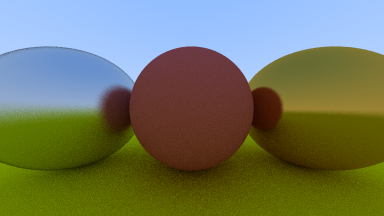

In [82]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    HittablesWithMat(scene_with_fuzzymetal_spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

## 10. Dielectrics

### 10.2. Snell's Law

屈折率$\eta$,$\eta'$の媒質に対して法線からの光の角度がそれぞれ$\theta$,$\theta'$で表されるとき
$$
    \eta \cdot \sin{\theta} = \eta' \cdot \sin{\theta'}
$$
が成り立つ。（屈折率は空気を1.0とし、ガラスが1.3-1.7、ダイヤモンドが2.4程度）

これらを用いて屈折後の角度$\sin{\theta'}$は
$$
    \sin{\theta'} = \frac{\eta}{\eta'}\cdot\sin{\theta}
$$
と表される。

これを使って屈折後のレイのベクトルを求める。入射レイと屈折レイを$\boldsymbol{R}$,$\boldsymbol{R'}$として、法線を$\boldsymbol{n'}$とする。
これらは全て単位ベクトルである。$\boldsymbol{R'}$を$\boldsymbol{n'}$と平行な成分$\boldsymbol{R'_\parallel}$と垂直な成分$\boldsymbol{R'_\perp}$に分けると
$$
    \boldsymbol{R'} = \boldsymbol{R'_\parallel} + \boldsymbol{R'_\perp}
$$
が成立する。
幾何的な関係から
$$
    \boldsymbol{R'_\parallel} = \frac{\eta}{\eta'}(R+\cos{\theta}\boldsymbol{n}) \\
    \boldsymbol{R'_\perp} = -\sqrt{1-|\boldsymbol{R'_\parallel}|^2\boldsymbol{n}}
$$
さらに$\cos{\theta}$をベクトルで表す必要がある。
よく知られているように、二つのベクトルの積はそれらがなす角度のコサインを使って表せる。
$$
    \boldsymbol{a}\cdot\boldsymbol{b} = |a||b|\cos{\theta}
$$
さらに$\boldsymbol{a}$と$\boldsymbol{b}$が単位ベクトルなら
$$
    \boldsymbol{a}\cdot\boldsymbol{b} = \cos{\theta}
$$

$\boldsymbol{R}$と$\boldsymbol{n}$は単位ベクトルなので、$\boldsymbol{R'_\parallel}$を既知の記号だけを使って表せる。
$$
    \boldsymbol{R'_\parallel} = \frac{\eta}{\eta'}(\boldsymbol{R}+(-\boldsymbol{R}\cdot\boldsymbol{n})\boldsymbol{n})
$$

In [83]:
function refract(uv::C, n::C, etai_over_etat::T)::C where {T <: AbstractFloat, C <: AbstractVector{T}}
    cos_theta = dot(-uv, n)
    r_out_parallel = etai_over_etat * (uv + cos_theta*n)
    r_out_perp = -sqrt(abs(one(T) - dot(r_out_parallel, r_out_parallel))) * n
    return r_out_parallel + r_out_perp
end

refract (generic function with 1 method)

In [84]:
struct Dielectric{T} <: Material
    ref_idx::T
end

In [85]:
function scatter(ray_in::Ray{T, C},
        rec::InnerHitRecordWithMat{T, C, Dielectric{T}},
        random_generator::AbstractRNG
        )::Tuple{Ray{T, C}, RGB{T}, Bool} where {T <: AbstractFloat, C <: AbstractVector{T}}
    etai_over_etat = rec.material.ref_idx
    unit_direction = convert_to_unit_vector(ray_in.direction)
    refracted = refract(unit_direction, rec.normal, etai_over_etat)
    scattered = Ray(rec.posiotion, refracted)
    return (scattered, RGB(one(T), one(T), one(T)), true)
end

scatter (generic function with 4 methods)

In [86]:
function scatter(ray_in::Ray{T, C},
        rec::OuterHitRecordWithMat{T, C, Dielectric{T}},
        random_generator::AbstractRNG
        )::Tuple{Ray{T, C}, RGB{T}, Bool} where {T <: AbstractFloat, C <: AbstractVector{T}}
    etai_over_etat = one(T) / rec.material.ref_idx
    unit_direction = convert_to_unit_vector(ray_in.direction)
    refracted = refract(unit_direction, rec.normal, etai_over_etat)
    scattered = Ray(rec.position, refracted)
    return (scattered, RGB(one(T), one(T), one(T)), true)
end

scatter (generic function with 5 methods)

In [87]:
mat_ground = Lambertian(RGB(0.8, 0.8, 0.0))
mat_center = Dielectric(1.5)
mat_left = Dielectric(1.5)
mat_right = FuzzyMetal(RGB(0.8, 0.6, 0.2), 0.1)

scene_with_dielectric_spheres = [SphereWithMat([0.0, -100.5, -1.0], 100.0, mat_ground),
    SphereWithMat([0.0, 0.0, -1.0], 0.5, mat_center),
    SphereWithMat([-1.0, 0.0, -1.0], 0.5, mat_left),
    SphereWithMat([1.0, 0.0, -1.0], 0.5, mat_right)]

4-element Vector{SphereWithMat{Float64, Vector{Float64}}}:
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.0, -100.5, -1.0], 100.0, Lambertian{Float64}(RGB{Float64}(0.8,0.8,0.0)))
 SphereWithMat{Float64, Vector{Float64}, Dielectric{Float64}}([0.0, 0.0, -1.0], 0.5, Dielectric{Float64}(1.5))
 SphereWithMat{Float64, Vector{Float64}, Dielectric{Float64}}([-1.0, 0.0, -1.0], 0.5, Dielectric{Float64}(1.5))
 SphereWithMat{Float64, Vector{Float64}, FuzzyMetal{Float64}}([1.0, 0.0, -1.0], 0.5, FuzzyMetal{Float64}(RGB{Float64}(0.8,0.6,0.2), 0.1))

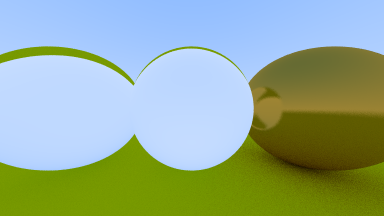

In [88]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    HittablesWithMat(scene_with_dielectric_spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

### 10.3. Total Internal Reflection

In [89]:
function scatter(ray_in::Ray{T, C},
        rec::InnerHitRecordWithMat{T, C, Dielectric{T}},
        random_generator::AbstractRNG
        )::Tuple{Ray{T, C}, RGB{T}, Bool} where {T <: AbstractFloat, C <: AbstractVector{T}}
    pure_color = RGB(one(T), one(T), one(T))
    etai_over_etat = rec.material.ref_idx
    unit_direction = convert_to_unit_vector(ray_in.direction)
    cos_theta = min(dot(-unit_direction, rec.normal), 1.0)
    sin_theta = sqrt(one(T) - cos_theta*cos_theta)
    if etai_over_etat * sin_theta > one(T)
        reflected = reflect(unit_direction, rec.normal)
        scattered = Ray(rec.position, reflected)
        return (scattered, pure_color, true)
    else
        refracted = refract(unit_direction, rec.normal, etai_over_etat)
        scattered = Ray(rec.posiotion, refracted)
        return (scattered, pure_color, true)
    end
end

scatter (generic function with 5 methods)

In [90]:
function scatter(ray_in::Ray{T, C},
        rec::OuterHitRecordWithMat{T, C, Dielectric{T}},
        random_generator::AbstractRNG
        )::Tuple{Ray{T, C}, RGB{T}, Bool} where {T <: AbstractFloat, C <: AbstractVector{T}}
    pure_color = RGB(one(T), one(T), one(T))
    etai_over_etat = one(T) / rec.material.ref_idx
    unit_direction = convert_to_unit_vector(ray_in.direction)
    cos_theta = min(dot(-unit_direction, rec.normal), 1.0)
    sin_theta = sqrt(one(T) - cos_theta*cos_theta)
    if etai_over_etat * sin_theta > one(T)
        reflected = reflect(unit_direction, rec.normal)
        scattered = Ray(rec.position, reflected)
        return (scattered, pure_color, true)
    else
        refracted = refract(unit_direction, rec.normal, etai_over_etat)
        scattered = Ray(rec.position, refracted)
        return (scattered, pure_color, true)
    end
end

scatter (generic function with 5 methods)

In [91]:
mat_ground = Lambertian(RGB(0.8, 0.8, 0.0))
mat_center = Lambertian(RGB(0.1, 0.2, 0.5))
mat_left = Dielectric(1.5)
mat_right = FuzzyMetal(RGB(0.8, 0.6, 0.2), 0.1)

scene_with_dielectric_spheres = [SphereWithMat([0.0, -100.5, -1.0], 100.0, mat_ground),
    SphereWithMat([0.0, 0.0, -1.0], 0.5, mat_center),
    SphereWithMat([-1.0, 0.0, -1.0], 0.5, mat_left),
    SphereWithMat([1.0, 0.0, -1.0], 0.5, mat_right)]

4-element Vector{SphereWithMat{Float64, Vector{Float64}}}:
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.0, -100.5, -1.0], 100.0, Lambertian{Float64}(RGB{Float64}(0.8,0.8,0.0)))
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.0, 0.0, -1.0], 0.5, Lambertian{Float64}(RGB{Float64}(0.1,0.2,0.5)))
 SphereWithMat{Float64, Vector{Float64}, Dielectric{Float64}}([-1.0, 0.0, -1.0], 0.5, Dielectric{Float64}(1.5))
 SphereWithMat{Float64, Vector{Float64}, FuzzyMetal{Float64}}([1.0, 0.0, -1.0], 0.5, FuzzyMetal{Float64}(RGB{Float64}(0.8,0.6,0.2), 0.1))

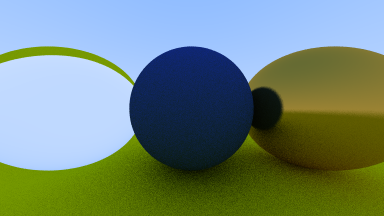

In [92]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    HittablesWithMat(scene_with_dielectric_spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

### 10.4. Schlick Approximation

In [93]:
function schlick(cosine::T, ref_idx::T)::T where T <: Number
    r0 = (one(T) - ref_idx) / (one(T) + ref_idx)
    sqr0 = r0 ^2
    return sqr0 + (one(T) - sqr0)*((one(T) - cosine)^5)
end

schlick (generic function with 1 method)

In [94]:
function scatter(ray_in::Ray{T, C},
        rec::InnerHitRecordWithMat{T, C, Dielectric{T}},
        random_generator::AbstractRNG
        )::Tuple{Ray{T, C}, RGB{T}, Bool} where {T <: AbstractFloat, C <: AbstractVector{T}}
    pure_color = RGB(one(T), one(T), one(T))
    etai_over_etat = rec.material.ref_idx
    unit_direction = convert_to_unit_vector(ray_in.direction)
    cos_theta = min(dot(-unit_direction, rec.normal), 1.0)
    sin_theta = sqrt(one(T) - cos_theta*cos_theta)
    cannot_refract = etai_over_etat * sin_theta > one(T)
    reflactance = schlick(cos_theta, etai_over_etat)
    if cannot_refract || reflactance > rand(random_generator, T)
        reflected = reflect(unit_direction, rec.normal)
        scattered = Ray(rec.position, reflected)
        return (scattered, pure_color, true)
    else
        refracted = refract(unit_direction, rec.normal, etai_over_etat)
        scattered = Ray(rec.position, refracted)
        return (scattered, pure_color, true)
    end
end

scatter (generic function with 5 methods)

In [95]:
function scatter(ray_in::Ray{T, C},
        rec::OuterHitRecordWithMat{T, C, Dielectric{T}},
        random_generator::AbstractRNG
        )::Tuple{Ray{T, C}, RGB{T}, Bool} where {T <: AbstractFloat, C <: AbstractVector{T}}
    pure_color = RGB(one(T), one(T), one(T))
    etai_over_etat = one(T) / rec.material.ref_idx
    unit_direction = convert_to_unit_vector(ray_in.direction)
    cos_theta = min(dot(-unit_direction, rec.normal), 1.0)
    sin_theta = sqrt(one(T) - cos_theta*cos_theta)
    cannot_refract = etai_over_etat * sin_theta > one(T)
    reflactance = schlick(cos_theta, etai_over_etat)
    if cannot_refract || reflactance > rand(random_generator, T)
        reflected = reflect(unit_direction, rec.normal)
        scattered = Ray(rec.position, reflected)
        return (scattered, pure_color, true)
    else
        refracted = refract(unit_direction, rec.normal, etai_over_etat)
        scattered = Ray(rec.position, refracted)
        return (scattered, pure_color, true)
    end
end

scatter (generic function with 5 methods)

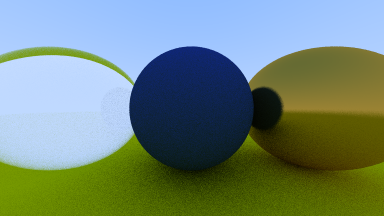

In [96]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    HittablesWithMat(scene_with_dielectric_spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

### 10.5. Modeling a Hollow Glass Sphere

In [97]:
mat_ground = Lambertian(RGB(0.8, 0.8, 0.0))
mat_center = Lambertian(RGB(0.1, 0.2, 0.5))
mat_left = Dielectric(1.5)
mat_right = FuzzyMetal(RGB(0.8, 0.6, 0.2), 0.1)

scene_with_hollow_glass_spheres = [SphereWithMat([0.0, -100.5, -1.0], 100.0, mat_ground),
    SphereWithMat([0.0, 0.0, -1.0], 0.5, mat_center),
    SphereWithMat([-1.0, 0.0, -1.0], 0.5, mat_left),
    SphereWithMat([-1.0, 0.0, -1.0], -0.45, mat_left),
    SphereWithMat([1.0, 0.0, -1.0], 0.5, mat_right)]

5-element Vector{SphereWithMat{Float64, Vector{Float64}}}:
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.0, -100.5, -1.0], 100.0, Lambertian{Float64}(RGB{Float64}(0.8,0.8,0.0)))
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.0, 0.0, -1.0], 0.5, Lambertian{Float64}(RGB{Float64}(0.1,0.2,0.5)))
 SphereWithMat{Float64, Vector{Float64}, Dielectric{Float64}}([-1.0, 0.0, -1.0], 0.5, Dielectric{Float64}(1.5))
 SphereWithMat{Float64, Vector{Float64}, Dielectric{Float64}}([-1.0, 0.0, -1.0], -0.45, Dielectric{Float64}(1.5))
 SphereWithMat{Float64, Vector{Float64}, FuzzyMetal{Float64}}([1.0, 0.0, -1.0], 0.5, FuzzyMetal{Float64}(RGB{Float64}(0.8,0.6,0.2), 0.1))

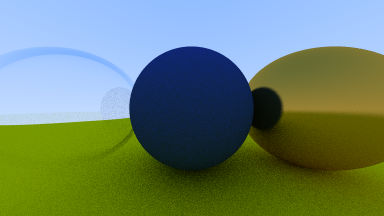

In [98]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    HittablesWithMat(scene_with_hollow_glass_spheres),
    def_cam,
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

## 11. Positionable Camera

### 11.1. Camera Viewing Geometry

In [99]:
struct VFoVableCamera{T <: Number, U <: Unsigned, C <: AbstractVector{T}}
    image_height::U
    image_width::U
    origin::C
    horizontal::C
    vertical::C
    lower_left_corner::C
end

In [100]:
function VFoVableCamera(T::Type{<: Number},
        vfov::U,
        image_height::U, image_width::U
        )::VFoVableCamera where U <: Unsigned
    aspect_ratio = T(image_width)/T(image_height)
    theta = deg2rad(vfov)
    h = tan(theta/2)
    viewport_height = 2h
    viewport_width = aspect_ratio * viewport_height
    focal_length = one(T)
    origin = [zero(T), zero(T), zero(T)]
    horizontal = [viewport_width, zero(T), zero(T)]
    vertical = [zero(T), viewport_height, zero(T)]
    return VFoVableCamera(image_height,
        image_width,
        origin,
        horizontal,
        vertical,
        calc_lower_left_corner(focal_length, origin, horizontal, vertical))
end

VFoVableCamera

In [101]:
R = cos(π/4)
RT = typeof(R)
vfov_world = [
    SphereWithMat(
        [-R, zero(RT), -one(RT)], R,
        Lambertian(RGB(zero(RT), zero(RT), one(RT)))),
    SphereWithMat(
        [R, zero(RT), -one(RT)], R,
        Lambertian(RGB(one(RT), zero(RT), zero(RT))))]

2-element Vector{SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}}:
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([-0.7071067811865476, 0.0, -1.0], 0.7071067811865476, Lambertian{Float64}(RGB{Float64}(0.0,0.0,1.0)))
 SphereWithMat{Float64, Vector{Float64}, Lambertian{Float64}}([0.7071067811865476, 0.0, -1.0], 0.7071067811865476, Lambertian{Float64}(RGB{Float64}(1.0,0.0,0.0)))

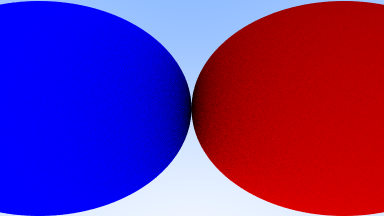

In [102]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    HittablesWithMat(vfov_world),
    VFoVableCamera(Float64, UInt(90), image_height, image_width),
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

### 11.2. Positioning and Orienting the Camera

In [103]:
struct LookableCamera{T <: Number, U <: Unsigned, C <: AbstractVector{T}}
    image_height::U
    image_width::U
    origin::C
    horizontal::C
    vertical::C
    lower_left_corner::C
end

In [104]:
function LookableCamera(lookfrom::C, lookat::C, vup::C,
        vfov::T,
        image_height::U,
        image_width::U
        )::LookableCamera{T, U, C} where {T <: Number, U <: Unsigned, C <: AbstractVector{T}}
    aspect_ratio = T(image_width)/T(image_height)
    theta = deg2rad(vfov)
    h = tan(theta/2)
    viewport_height = 2h
    viewport_width = aspect_ratio * viewport_height

    w = convert_to_unit_vector(lookfrom - lookat)
    u = convert_to_unit_vector(cross(vup,  w))
    v = cross(w, u)

    origin = lookfrom
    horizontal = viewport_width * u
    vertical = viewport_height * v
    return LookableCamera(image_height,
        image_width,
        origin,
        horizontal,
        vertical,
        origin - horizontal ./ 2 - vertical ./ 2 - w)
end

LookableCamera

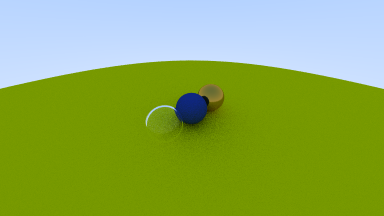

In [105]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    HittablesWithMat(scene_with_hollow_glass_spheres),
    LookableCamera([-2.0, 2.0, 1.0],
        [0.0, 0.0, -1.0],
        [0.0, 1.0, 0.0],
        90.0, image_height, image_width),
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

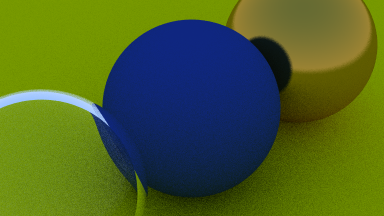

In [106]:
render_color!(calc_uv!,
    get_ray,
    ray_color,
    HittablesWithMat(scene_with_hollow_glass_spheres),
    LookableCamera([-2.0, 2.0, 1.0],
        [0.0, 0.0, -1.0],
        [0.0, 1.0, 0.0],
        20.0, image_height, image_width),
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer

## 12. Defocus Blur

### 12.1. A thin Lens Approximation

### 12.2. Generating Sample Rays

In [107]:
function random_in_unit_disk(random_generator::AbstractRNG)
    T = Float64
    while true
        p = [signed_unit_random(T, random_generator), signed_unit_random(T, random_generator), zero(T)]
        if dot(p, p) >= one(T)
            continue
        else
            return p
        end
    end
end

random_in_unit_disk (generic function with 1 method)

In [108]:
struct LensCamera{T <: Number, U <: Unsigned, C <: AbstractVector{T}}
    image_height::U
    image_width::U
    origin::C
    horizontal::C
    vertical::C
    lower_left_corner::C
    u::C
    v::C
    w::C
    lens_radius::T
end

In [109]:
function LensCamera(lookfrom::C, lookat::C, vup::C,
        vfov::T,
        image_height::U,
        image_width::U,
        aperture::T,
        focus_dist::T
        )::LensCamera{T, U, C} where {T <: Number, U <: Unsigned, C <: AbstractVector{T}}
    aspect_ratio = T(image_width)/T(image_height)
    theta = deg2rad(vfov)
    h = tan(theta/2)
    viewport_height = 2h
    viewport_width = aspect_ratio * viewport_height

    w = convert_to_unit_vector(lookfrom - lookat)
    u = convert_to_unit_vector(cross(vup,  w))
    v = cross(w, u)

    origin = lookfrom
    horizontal = focus_dist * viewport_width * u
    vertical = focus_dist * viewport_height * v
    lower_left_corner = origin - horizontal ./ 2 - vertical ./ 2 - focus_dist * w
    
    lens_radius = aperture / 2
    return LensCamera(image_height,
        image_width,
        origin,
        horizontal,
        vertical,
        lower_left_corner,
        u,v,w,lens_radius)
end

LensCamera

In [110]:
function get_ray(camera::LensCamera,
        s::T, t::T,
        random_generator::AbstractRNG
        )::Ray where {T <: Number}
    rd = camera.lens_radius * random_in_unit_disk(random_generator)
    offset = camera.u * rd[1] + camera.v * rd[2]

    return Ray(camera.origin + offset,
        camera.lower_left_corner
        + s .* camera.horizontal
        + t .* camera.vertical
        - camera.origin - offset)
end

get_ray (generic function with 2 methods)

In [114]:
function render_color!(calc_uv!,
        ray_color,
        hittable,
        camera::LensCamera{T, U},
        samples_per_pixel::U,
        max_depth::V,
        random_generator::AbstractRNG,
        buffer::C
        )::C where {T <: AbstractFloat, U <: Unsigned, V <: Signed,
            C <: AbstractMatrix{RGB{T}}}
    for i = 1:camera.image_width
        for j = 1:camera.image_height
            color = zero(RGB)
            for s = 1:samples_per_pixel
                color += ray_color(hittable,
                    get_ray(camera,
                        calc_uv!(T, camera, i, j, random_generator)...,
                        random_generator),
                max_depth,
                random_generator)
            end
            color = color ./ samples_per_pixel
            pixel = RGB(clamp(color.r, zero(T), one(T)),
                clamp(color.g, zero(T), one(T)),
                clamp(color.b, zero(T), one(T)))
            buffer[j, i] = pixel
        end
    end
    return buffer
end

render_color! (generic function with 7 methods)

In [112]:
const lookfrom = [3.0, 3.0, 2.0]
const lookat = [0.0, 0.0, -1.0]
const ll = lookfrom - lookat
const dist_to_focus = dot(ll, ll) |> sqrt

5.196152422706632

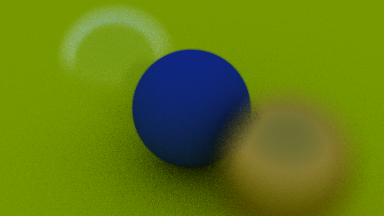

In [115]:
render_color!(calc_uv!,
    ray_color,
    HittablesWithMat(scene_with_hollow_glass_spheres),
    LensCamera(lookfrom,
        lookat,
        [0.0, 1.0, 0.0],
        20.0,
        image_height, image_width,
        2.0,
        dist_to_focus),
    samples_per_pixel,
    max_depth,
    random_generator,
    buffer)
buffer